<a href="https://colab.research.google.com/github/MalezhykDaniil/ML/blob/main/%D0%9B%D0%A012_RNN_LSTM_%D0%9C%D0%B0%D0%BB%D0%B5%D0%B6%D0%B8%D0%BA_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 12
## Рекурентні нейронні мережі (RNN, LSTM). Генерація тексту та підбір гіперпараметрів

**ПІБ студента:** Малежик Данііл
**Група:** 3-10  
**Дата:** 20.11.2026

### Мета роботи
Ознайомитися з принципами обробки текстових послідовностей за допомогою **SimpleRNN** та **LSTM**, навчитися підготовлювати текстові дані, будувати й навчати модель передбачення наступного слова, генерувати текст і підбирати гіперпараметри за допомогою **Keras Tuner**.

### Очікуваний результат
- Побудована й навчена модель `Embedding → SimpleRNN → LSTM → Dropout → Dense`.
- Графіки втрат і точності, приклад згенерованого тексту.
- Результат автоматичного підбору гіперпараметрів і порівняння двох моделей.

**Інструкція:** виконуйте кроки послідовно, заповнюйте порожні комірки Python власним кодом. Не видаляйте результати запуску — вони потрібні для перевірки. Рекомендоване середовище: Google Colab або Jupyter Notebook з TensorFlow.

## Частина 1. Створення моделі для передбачення наступного слова

### 1. Імпорт бібліотек
Імпортуйте:
- `numpy` як `np`, `matplotlib.pyplot` як `plt`;
- `Sequential` із `tensorflow.keras.models`;
- `Dense`, `SimpleRNN`, `LSTM`, `Embedding`, `Dropout`;
- `Tokenizer` із `tensorflow.keras.preprocessing.text`;
- `to_categorical` із `tensorflow.keras.utils`.

**Завдання:** переконайтеся, що всі бібліотеки імпортуються без помилок.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Embedding, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical

### 2. Вхідний текст для навчання
Створіть рядкову змінну `texts` із наведеним фрагментом вірша. Саме цей текст використовується у вихідному прикладі лабораторної роботи.

```text
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..
```

**Завдання:** виведіть початковий текст або перші 100 його символів.

In [2]:
texts = """
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..
"""

### 3. Попередня обробка та токенізація
1. Видаліть із `texts` можливий символ `\ufeff`.
2. Задайте `maxWordsCount = 1000`.
3. Створіть `Tokenizer` із такими налаштуваннями: `num_words=maxWordsCount`, `lower=True`, `split=' '`, `char_level=False`. Для `filters` використайте набір знаків пунктуації з вихідного прикладу, зокрема `!`, `?`, `.`, `,`, тире та лапки.
4. Навчіть токенізатор на тексті за допомогою `fit_on_texts()`.
5. Виведіть кількість знайдених унікальних слів та кілька відповідностей зі словника `word_index`.

**Підказка:** метод `fit_on_texts()` будує словник відповідностей слів і числових індексів.

In [5]:
texts = texts.replace('\ufeff', '')

maxWordsCount = 1000
tokenizer = Tokenizer(num_words=maxWordsCount, filters='!–"—#$%&;()*+,-./:;<=>?@[\\]^_`{|}~\t\n\r«»',
                      lower=True, split=' ', char_level=False)
tokenizer.fit_on_texts([texts])

unique_words_count = len(tokenizer.word_index)
print(f'Кількість знайдених унікальних слів: {unique_words_count}')

sample_word_index = list(tokenizer.word_index.items())[:10]
print('Приклади відповідностей (слово -> індекс):', sample_word_index)

Кількість знайдених унікальних слів: 35
Приклади відповідностей (слово -> індекс): [('не', 1), ('лихо', 2), ('на', 3), ('чом', 4), ('вас', 5), ('в', 6), ('думи', 7), ('мої', 8), ('як', 9), ('мені', 10)]


### 4. Формування навчальної вибірки
Перетворіть текст на послідовність цілих чисел методом `texts_to_sequences()` і збережіть числову послідовність у змінній `res` як масив NumPy.

Задайте **`inp_words = 3`**. Сформуйте:
- `X` — послідовності з **трьох** сусідніх слів;
- `Y` — **наступне слово** після кожної послідовності у форматі one-hot (`to_categorical`, `num_classes=maxWordsCount`).

Перевірте розміри `X` і `Y`, виведіть перший приклад та його цільове слово.

**Підказка:** кількість навчальних прикладів дорівнює `len(res) - inp_words`.

In [7]:
data = tokenizer.texts_to_sequences([texts])
res = np.array(data[0])

inp_words = 3
n = res.shape[0] - inp_words

X = np.array([res[i:i + inp_words] for i in range(n)])
Y = to_categorical(res[inp_words:], num_classes=maxWordsCount)

print('Розмір X:', X.shape)
print('Розмір Y:', Y.shape)

first_x_ids = X[0]
first_y_id = int(np.argmax(Y[0]))

index_word = tokenizer.index_word

first_x_words = [index_word.get(idx, '<OOV/filtered>') for idx in first_x_ids]
first_y_word = index_word.get(first_y_id, '<OOV/filtered>')

print('Перший приклад (індекси X[0]):', first_x_ids)
print('Перший приклад (слова):', first_x_words)
print('Цільове слово (індекс Y[0]):', first_y_id)
print('Цільове слово:', first_y_word)

Розмір X: (49, 3)
Розмір Y: (49, 1000)
Перший приклад (індекси X[0]): [7 8 7]
Перший приклад (слова): ['думи', 'мої', 'думи']
Цільове слово (індекс Y[0]): 8
Цільове слово: мої


### 5. Побудова рекурентної нейронної мережі
Створіть модель `Sequential` із такою архітектурою (як у вихідному ноутбуці):

1. `Embedding(maxWordsCount, 300, input_length=inp_words)` — векторні представлення слів;
2. `SimpleRNN(128, activation='tanh', return_sequences=True)`;
3. `LSTM(128, activation='tanh')`;
4. `Dropout(0.2)`;
5. `Dense(128, activation='relu')`;
6. `Dense(maxWordsCount, activation='softmax')`.

Збережіть модель у змінній `model`.

**Питання:** чому для `SimpleRNN` необхідний параметр `return_sequences=True`, якщо після нього йде шар `LSTM`?

In [11]:
model = Sequential()
model.add(Embedding(maxWordsCount, 300))
model.add(SimpleRNN(128, activation='tanh', return_sequences=True))
model.add(LSTM(128, activation='tanh'))
model.add(Dropout(0.2))
model.add(Dense(128, activation='relu'))
model.add(Dense(maxWordsCount, activation='softmax'))

Рекурентні шари обробляють послідовність крок за кроком. За замовчуванням у Keras стоїть return_sequences=False - тоді шар повертає лише вихід останнього часового кроку, перетворюючи 3D-тензор на 2D-тензор.

Але наступний шар у моделі - це LSTM, який очікує на вхід 3D-тензор, щоб теж пройтися по всій послідовності часових кроків:

return_sequences=True: SimpleRNN повертає прихований стан для кожного з 3 кроків послідовності - тензор форми (batch_size, 3, 128). LSTM отримує цю послідовність ознак і продовжує її рекурентну обробку.

Якби було return_sequences=False: SimpleRNN видав би лише один вектор на приклад - (batch_size, 128). LSTM не зміг би обробити такий 2D-вхід і викликав би помилку розмірності (ValueError: Input 0 of layer ... is incompatible with the layer: expected ndim=3, found ndim=2).

Натомість у шару LSTM параметр return_sequences за замовчуванням дорівнює False, тому він уже «згортає» послідовність у один вектор для подальшої передачі у Dropout і повнозв'язні шари Dense.

### 6. Компіляція та перегляд архітектури
Скомпілюйте `model` із параметрами:
- оптимізатор — `adam`;
- функція втрат — `categorical_crossentropy`;
- метрика — `accuracy`.

Виведіть `model.summary()` і запишіть кількість параметрів моделі.

In [12]:
model.compile(loss='categorical_crossentropy', metrics=['accuracy'], optimizer='adam')
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### 7. Навчання моделі
Навчіть модель на `X` та `Y` із параметрами **`batch_size=32`** і **`epochs=50`**. Збережіть історію навчання у змінну `history`.

**Завдання:** виведіть значення точності та функції втрат для останньої епохи.

In [13]:
history = model.fit(X, Y, batch_size=32, epochs=50)

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - accuracy: 0.0000e+00 - loss: 6.9069
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.2857 - loss: 6.8937 
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.5102 - loss: 6.8792
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.5306 - loss: 6.8599
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.4898 - loss: 6.8278
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.4490 - loss: 6.7832
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.4286 - loss: 6.7005
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.3265 - loss: 6.5485
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.2653 - loss: 6.2438
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.1429 - loss: 5.7341
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.1429 - loss: 4.9266
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.0612 - loss: 4.0

### 8. Візуалізація навчання
Використовуючи `history.history`, побудуйте **два графіки поруч**:
- функція втрат `loss` залежно від епохи;
- точність `accuracy` залежно від епохи.

Додайте назви графіків, підписи осей і легенди.

**Короткий аналіз:** як змінювалися `loss` та `accuracy`? Чи достатньо цих графіків, щоб оцінити якість моделі на новому тексті?

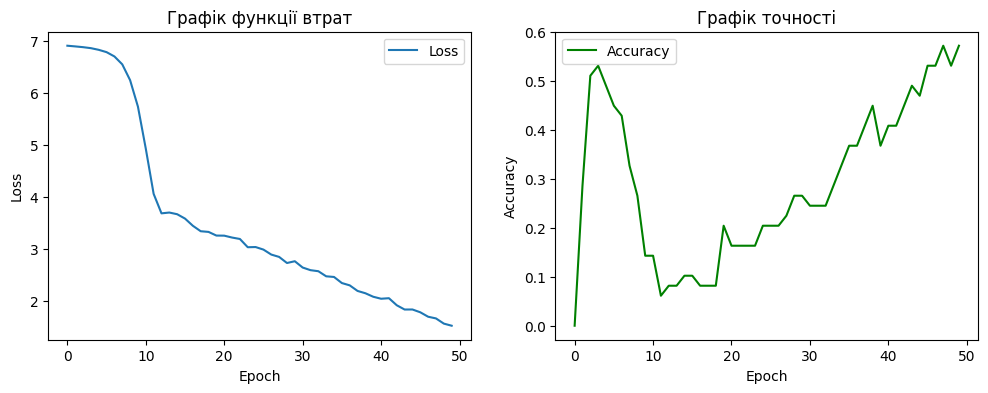

In [14]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Графік функції втрат')

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Accuracy', color='green')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Графік точності')

plt.show()

Функція втрат (Loss): Починається приблизно з ~6.9. До ~6–7-ї епохи спадає повільно, потім між ~7-ю та 12-ю епохою різко падає приблизно до ~3.7, а далі стабільно й поступово знижується до ~1.5 на 50-й епосі.

Точність (Accuracy): Поведінка нелінійна — спочатку різко зростає до ~0.53 (близько 3-ї епохи), потім просідає до ~0.06 (близько 11-ї епохи), утримується в межах ~0.06–0.20 до ~19-ї епохи, а згодом у цілому зростає з невеликими коливаннями приблизно до ~0.57–0.58 ближче до кінця навчання.

Чи достатньо цих графіків для оцінки якості на новому тексті? Ні, недостатньо, з кількох причин:

Немає валідаційної / тестової вибірки (val_loss, val_accuracy): Графіки показують лише якість на навчальних даних. Модель із SimpleRNN + LSTM та великою кількістю параметрів (зокрема через Embedding(..., 300) і вихідний шар Dense(maxWordsCount)) легко може перенавчатися (запам'ятовувати конкретні фрази з тренувального тексту), але погано узагальнювати на нових даних.  

Точність top-1 (accuracy) не відображає генеративну якість: У задачі передбачення наступного слова часто є кілька доречних варіантів продовження фрази, тому модель може генерувати цілком природний текст навіть за помірної accuracy, або навпаки - повторювати часті слова/кліше.Потрібна практична перевірка: Щоб оцінити роботу на новому тексті, варто перевірити метрики на відкладеній валідаційній/тестовій вибірці і протестувати генерацію тексту на нових стартових фразах.

### 9. Генерація нового тексту
Реалізуйте функцію **`buildPhrase(texts, str_len=20)`**, яка:
1. Перетворює початковий текст на індекси слів за допомогою `tokenizer`;
2. На кожному кроці передає моделі **останні `inp_words` індексів**;
3. Отримує прогноз `model.predict()`, визначає індекс найбільш імовірного слова через `argmax`;
4. Додає нове слово до послідовності, використовуючи `tokenizer.index_word`;
5. Повертає згенеровану фразу.

Перевірте роботу функції на початковій фразі **`"Думи мої думи"`**, згенеруйте **20 слів**.

**Зверніть увагу:** початкова фраза має містити щонайменше три відомі токенізатору слова. Якщо слово не знайдено, передбачте зрозумілу обробку цього випадку.

In [15]:
def buildPhrase(texts, str_len=20):
    res = texts
    data = tokenizer.texts_to_sequences([texts])[0]
    for i in range(str_len):
        x = data[i: i + inp_words]
        inp = np.expand_dims(x, axis=0)

        pred = model.predict(inp)
        indx = pred.argmax(axis=1)[0]
        data.append(indx)

        res += " " + tokenizer.index_word.get(indx, '')

    return res

res = buildPhrase("Думи мої думи")
print(res)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
Думи мої думи лихо лихо лихо на на на сміх сміх породило сльози сльози чом як не не в в в як як


## Частина 2. Автоматичний підбір гіперпараметрів (Keras Tuner)

### 10. Встановлення та імпорт Keras Tuner
У Google Colab або Jupyter Notebook встановіть (за потреби) пакет `keras-tuner`. Імпортуйте його під псевдонімом `kt`.

**Підказка:** для встановлення пакета в ноутбуці використовуйте `%pip install keras-tuner`.

Повторно створювати `X` та `Y` не потрібно: використайте вибірку з Частини 1.

In [20]:
!pip install keras-tuner

import keras_tuner as kt

### 11. Створення функції `build_model(hp)`
Опишіть функцію, яка будує та компілює модель і дає змогу змінювати гіперпараметри:

| Гіперпараметр | Простір пошуку |
|---|---|
| `embedding_dim` | від 128 до 512, крок 64 |
| `rnn_units` | від 64 до 256, крок 64 |
| `lstm_units` | від 64 до 256, крок 64 |
| `dropout_rate` | від 0.1 до 0.5, крок 0.1 |
| `dense_units` | від 64 до 256, крок 64 |
| `optimizer` | `adam` або `rmsprop` |

Збережіть структуру шарів із Частини 1: `Embedding → SimpleRNN → LSTM → Dropout → Dense → Dense`.

**Підказка:** використовуйте `hp.Int()`, `hp.Float()` і `hp.Choice()`; останній шар має `maxWordsCount` нейронів із `softmax`. Функція `build_model(hp)` повинна повертати скомпільовану модель.

In [17]:
def build_model(hp):
    model = Sequential()
    model.add(Embedding(maxWordsCount, hp.Int('embedding_dim', 128, 512, step=64), input_length=inp_words))
    model.add(SimpleRNN(hp.Int('rnn_units', 64, 256, step=64), activation='tanh', return_sequences=True))
    model.add(LSTM(hp.Int('lstm_units', 64, 256, step=64), activation='tanh'))
    model.add(Dropout(hp.Float('dropout_rate', 0.1, 0.5, step=0.1)))
    model.add(Dense(hp.Int('dense_units', 64, 256, step=64), activation='relu'))
    model.add(Dense(maxWordsCount, activation='softmax'))

    model.compile(
        loss='categorical_crossentropy',
        metrics=['accuracy'],
        optimizer=hp.Choice('optimizer', ['adam', 'rmsprop'])
    )
    return model

### 12. Пошук найкращих параметрів
Створіть `kt.RandomSearch` із такими налаштуваннями, як у вихідному прикладі:
- `hypermodel=build_model` (або передайте `build_model` першим аргументом);
- `objective='accuracy'`;
- `max_trials=10`;
- `executions_per_trial=1`;
- `directory='my_tuning'`, `project_name='text_prediction'`.

Запустіть `tuner.search(X, Y, epochs=10, batch_size=32)`.

**Завдання:** отримайте найкращий набір параметрів через `get_best_hyperparameters(num_trials=1)` і виведіть значення всіх шести гіперпараметрів.

**Примітка:** у вихідному прикладі підбір здійснюється за *навчальною* точністю. Це навчальна демонстрація; для об’єктивнішого порівняння зазвичай використовують окрему валідаційну вибірку.

In [21]:
tuner = kt.RandomSearch(
    build_model,
    objective='accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory='my_tuning',
    project_name='text_prediction'
)

tuner.search(X, Y, epochs=10, batch_size=32)

Trial 10 Complete [00h 00m 05s]
accuracy: 0.16326530277729034

Best accuracy So Far: 0.4693877696990967
Total elapsed time: 00h 00m 53s


### 13. Навчання моделі з підібраними параметрами
Створіть нову модель із найкращими параметрами (`tuner.hypermodel.build(best_hps)`), збережіть її у змінній `best_model`.

Навчіть `best_model` на `X`, `Y` із `batch_size=32`, `epochs=50`. Історію збережіть у `best_history`.

Виведіть `best_model.summary()`, а також кінцеві значення `loss` і `accuracy`.

In [25]:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print(f"""
Найкращі параметри:
Embedding Dimension: {best_hps.get('embedding_dim')}
RNN Units: {best_hps.get('rnn_units')}
LSTM Units: {best_hps.get('lstm_units')}
Dropout Rate: {best_hps.get('dropout_rate')}
Dense Units: {best_hps.get('dense_units')}
Optimizer: {best_hps.get('optimizer')}
""")

best_model = tuner.hypermodel.build(best_hps)

history = best_model.fit(X, Y, batch_size=32, epochs=50)

best_model.summary()
final_loss = history.history['loss'][-1]
final_accuracy = history.history['accuracy'][-1]

print(f'\nКінцеве значення loss (після {len(history.history["loss"])} епох): {final_loss:.4f}')
print(f'Кінцеве значення accuracy (після {len(history.history["accuracy"])} епох): {final_accuracy:.4f}')


Найкращі параметри:
Embedding Dimension: 256
RNN Units: 256
LSTM Units: 256
Dropout Rate: 0.30000000000000004
Dense Units: 128
Optimizer: adam

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.0000e+00 - loss: 6.9064
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.2449 - loss: 6.8899
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.3061 - loss: 6.8669
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.2653 - loss: 6.8300
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.2245 - loss: 6.7665
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.1224 - loss: 6.6416
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.1224 - loss: 6.3547
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.1020 - loss: 5.7394
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.1020 - loss: 4.7554
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 0.1020 - loss: 4.1058
Epoch 11/50
2/2 ━━━━

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 3, 256)         │       256,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_4 (SimpleRNN)        │ (None, 3, 256)         │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 256)            │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,223,610 (12.30 MB)

 Trainable params: 1,074,536 (4.10 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,149,074 (8.20 MB)


Кінцеве значення loss (після 50 епох): 0.5091
Кінцеве значення accuracy (після 50 епох): 0.9184


### 14. Графіки та генерація тексту після підбору
1. Побудуйте графіки `loss` і `accuracy` для `best_history`.
2. Порівняйте фінальні навчальні показники `model` та `best_model` в одному невеликому виводі або таблиці.
3. Згенеруйте **20 слів** із початкової фрази **`"Думи мої думи"`** за допомогою `best_model` (адаптуйте створену функцію або передайте модель їй як аргумент).
4. Порівняйте два згенеровані тексти.

**Зверніть увагу:** на такому невеликому тексті результати можуть бути нестабільними, а висока навчальна точність не означає якісної генерації нових фраз.

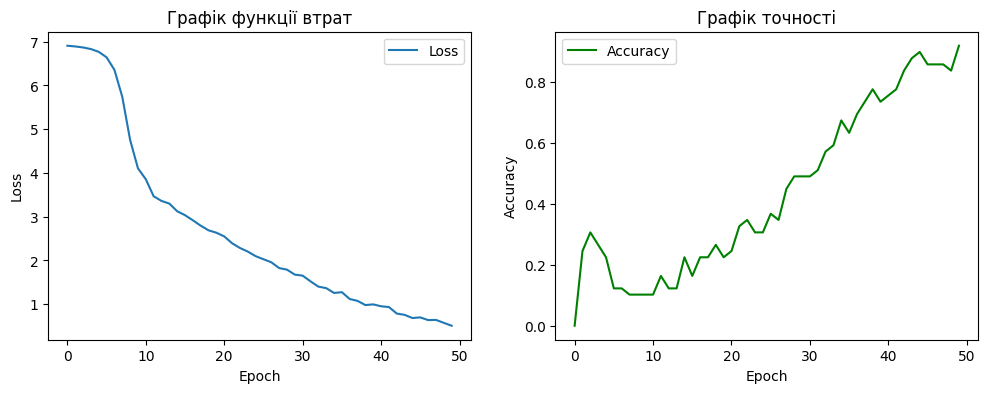

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_4 (Embedding)         │ (None, 3, 256)         │       256,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_4 (SimpleRNN)        │ (None, 3, 256)         │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 256)            │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,223,610 (12.30 MB)

 Trainable params: 1,074,536 (4.10 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,149,074 (8.20 MB)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 316ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину


In [26]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Графік функції втрат')

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Accuracy', color='green')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Графік точності')

plt.show()

best_model.summary()

def buildPhrase(texts, str_len=20):
    res = texts
    data = tokenizer.texts_to_sequences([texts])[0]
    for i in range(str_len):
        x = data[i: i + inp_words]
        inp = np.expand_dims(x, axis=0)

        pred = best_model.predict(inp)
        indx = pred.argmax(axis=1)[0]
        data.append(indx)

        res += " " + tokenizer.index_word.get(indx, '')
    return res

res = buildPhrase("Думи мої думи")
print(res)


## Висновки
Напишіть власний висновок **5–8 речень**, спираючись на отримані результати. Висвітліть:

1. Яку роль виконують шари `Embedding`, `SimpleRNN`, `LSTM` та `Dropout`?
2. Яких значень `loss` і `accuracy` досягла початкова модель?
3. Які гіперпараметри обрав Keras Tuner?
4. Чи покращилися навчальні показники після підбору параметрів?
5. Наскільки зв’язним був згенерований текст і чому обсяг корпусу важливий?

**Висновок студента:**

У цій лабораторній роботі шар Embedding перетворював індекси слів на щільні векторні представлення, SimpleRNN та LSTM опрацьовували послідовність із трьох слів для виявлення контекстних залежностей, а Dropout допомагав зменшувати перенавчання. Після 50 епох навчання початкова модель досягла значення loss близько 1.5218 і accuracy 0.5714. За допомогою Keras Tuner було обрано гіперпараметри: embedding_dim=256, rnn_units=256, lstm_units=256, dropout_rate=0.3, dense_units=128 та оптимізатор adam. Після підбору гіперпараметрів навчальні показники суттєво покращилися: best_model за 50 епох знизила loss до 0.5091 і підвищила accuracy до 0.9184. Водночас текст, згенерований початковою моделлю від фрази "Думи мої думи", вийшов уривчастим із повторами ("...лихо лихо лихо на на на сміх сміх..."), тоді як best_model відтворила майже весь початковий фрагмент вірша ("Думи мої думи мої лихо мені з вами нащо стали на папері сумними рядами чом вас вітер не розвіяв в степу як пилину"). Через малий корпус (35 унікальних слів і 49 навчальних прикладів) висока навчальна точність відображає насамперед запам'ятовування тренувального уривка

---

### Що потрібно здати
Заповнений файл `.ipynb` з усім власним кодом, результатами виконання, графіками, двома прикладами згенерованого тексту, знайденими гіперпараметрами та висновками.